# EDA for Credit Card Fraud Detection using MLG ULB Dataset

## Importing Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from collections import Counter

## Loading Data

In [2]:
df=pd.read_csv("creditcard.csv")

In [3]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)

## Checking Data

In [4]:
df.shape

(284807, 31)

In [5]:
df.head(5)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [6]:
df.tail(5)

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,4.356170,-1.593105,2.711941,-0.689256,4.626942,-0.924459,1.107641,1.991691,0.510632,-0.682920,1.475829,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,-0.975926,-0.150189,0.915802,1.214756,-0.675143,1.164931,-0.711757,-0.025693,-1.221179,-1.545556,0.059616,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,-0.484782,0.411614,0.063119,-0.183699,-0.510602,1.329284,0.140716,0.313502,0.395652,-0.577252,0.001396,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,-0.399126,-1.933849,-0.962886,-1.042082,0.449624,1.962563,-0.608577,0.509928,1.113981,2.897849,0.127434,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0
284806,172792.0,-0.533413,-0.189733,0.703337,-0.506271,-0.012546,-0.649617,1.577006,-0.414650,0.486180,-0.915427,-1.040458,-0.031513,-0.188093,-0.084316,0.041333,-0.302620,-0.660377,0.167430,-0.256117,0.382948,0.261057,0.643078,0.376777,0.008797,-0.473649,-0.818267,-0.002415,0.013649,217.00,0


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     284807 non-nu

In [8]:
df.columns

Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='str')

In [9]:
df.dtypes

Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64
V16       float64
V17       float64
V18       float64
V19       float64
V20       float64
V21       float64
V22       float64
V23       float64
V24       float64
V25       float64
V26       float64
V27       float64
V28       float64
Amount    float64
Class       int64
dtype: object

## Summary of Features

In [10]:
df.describe()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,2.238554e-15,1.724421e-15,-1.245415e-15,8.238900e-16,1.213481e-15,4.866699e-15,1.436219e-15,-3.768179e-16,9.707851e-16,1.036249e-15,6.418678e-16,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,1.088850e+00,1.020713e+00,9.992014e-01,9.952742e-01,9.585956e-01,9.153160e-01,8.762529e-01,8.493371e-01,8.381762e-01,8.140405e-01,7.709250e-01,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,-2.458826e+01,-4.797473e+00,-1.868371e+01,-5.791881e+00,-1.921433e+01,-4.498945e+00,-1.412985e+01,-2.516280e+01,-9.498746e+00,-7.213527e+00,-5.449772e+01,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,-5.354257e-01,-7.624942e-01,-4.055715e-01,-6.485393e-01,-4.255740e-01,-5.828843e-01,-4.680368e-01,-4.837483e-01,-4.988498e-01,-4.562989e-01,-2.117214e-01,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,-9.291738e-02,-3.275735e-02,1.400326e-01,-1.356806e-02,5.060132e-02,4.807155e-02,6.641332e-02,-6.567575e-02,-3.636312e-03,3.734823e-03,-6.248109e-02,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,4.539234e-01,7.395934e-01,6.182380e-01,6.625050e-01,4.931498e-01,6.488208e-01,5.232963e-01,3.996750e-01,5.008067e-01,4.589494e-01,1.330408e-01,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,2.374514e+01,1.201891e+01,7.848392e+00,7.126883e+00,1.052677e+01,8.877742e+00,1.731511e+01,9.253526e+00,5.041069e+00,5.591971e+00,3.942090e+01,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [11]:
for d in df:
    print(f"column name: {d}")
    print(f"No. of unique values: {df[d].nunique()}")
    print(f"Unique values: {df[d].unique()}")

column name: Time
No. of unique values: 124592
Unique values: [0.00000e+00 1.00000e+00 2.00000e+00 ... 1.72787e+05 1.72788e+05
 1.72792e+05]
column name: V1
No. of unique values: 275663
Unique values: [-1.35980713  1.19185711 -1.35835406 ...  1.91956501 -0.24044005
 -0.53341252]
column name: V2
No. of unique values: 275663
Unique values: [-0.07278117  0.26615071 -1.34016307 ... -0.30125385  0.53048251
 -0.18973334]
column name: V3
No. of unique values: 275663
Unique values: [ 2.53634674  0.16648011  1.77320934 ... -3.24963981  0.70251023
  0.70333737]
column name: V4
No. of unique values: 275663
Unique values: [ 1.37815522  0.44815408  0.37977959 ... -0.55782812  0.68979917
 -0.50627124]
column name: V5
No. of unique values: 275663
Unique values: [-0.33832077  0.06001765 -0.50319813 ...  2.63051512 -0.37796113
 -0.01254568]
column name: V6
No. of unique values: 275663
Unique values: [ 0.46238778 -0.08236081  1.80049938 ...  3.0312601   0.62370772
 -0.64961669]
column name: V7
No. of un

## Target Variable
Our target variable is binary and it's name is Class

In [12]:
df["Class"].value_counts(dropna=False)

Class
0    284315
1       492
Name: count, dtype: int64

In [13]:
df["Class"].value_counts(dropna=False, normalize=True) * 100

Class
0    99.827251
1     0.172749
Name: proportion, dtype: float64

## Missing and Inconsistent Values

In [14]:
missing=df.isnull().sum()
print("Columns containing missing values: ")
print(missing[missing>0])

Columns containing missing values: 
Series([], dtype: int64)


In [4]:
print(f"Duplicate Rows: {df.duplicated().sum()}")
df.drop_duplicates(inplace=True)

Duplicate Rows: 1081


In [16]:
infCount=np.isinf(df).sum()
print("Columns containing infinite values: ")
print(infCount[infCount>0])

Columns containing infinite values: 
Series([], dtype: int64)


In [17]:
df.shape

(283726, 31)

## Univariate Analysis

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\3340104099.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=df[d], palette="Set2", showmeans=True)


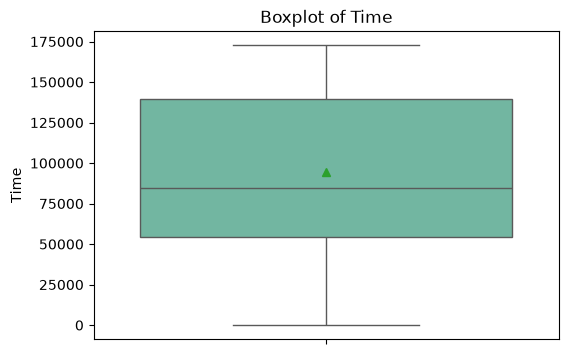

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\3340104099.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=df[d], palette="Set2", showmeans=True)


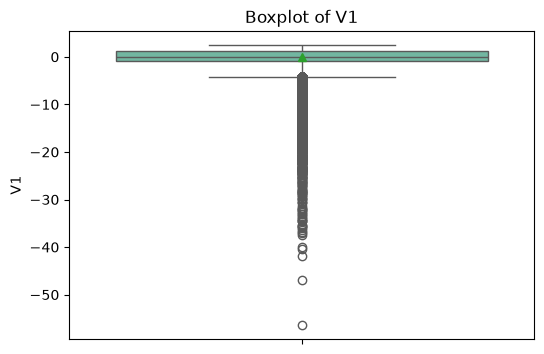

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\3340104099.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=df[d], palette="Set2", showmeans=True)


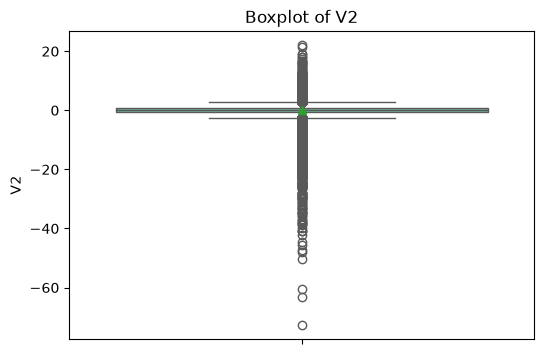

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\3340104099.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=df[d], palette="Set2", showmeans=True)


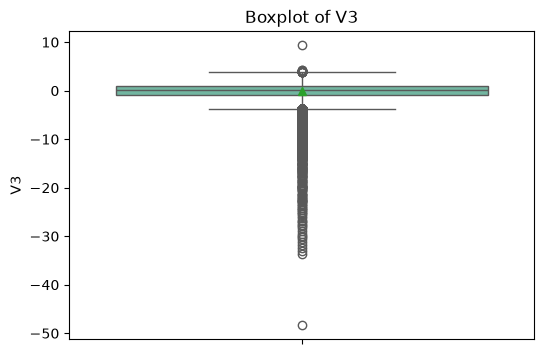

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\3340104099.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=df[d], palette="Set2", showmeans=True)


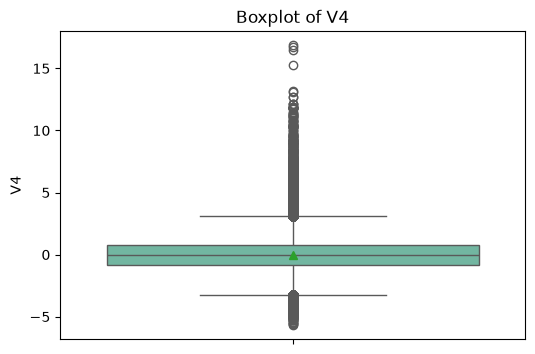

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\3340104099.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=df[d], palette="Set2", showmeans=True)


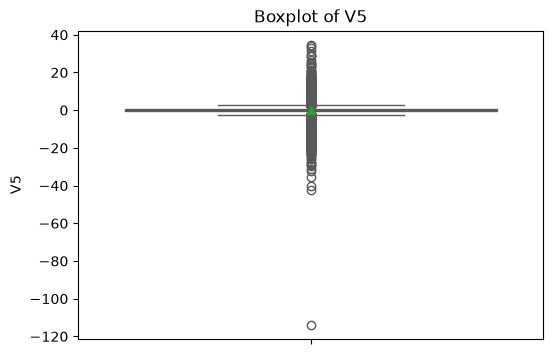

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\3340104099.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=df[d], palette="Set2", showmeans=True)


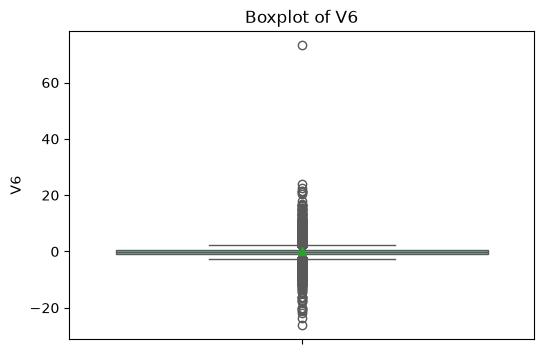

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\3340104099.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=df[d], palette="Set2", showmeans=True)


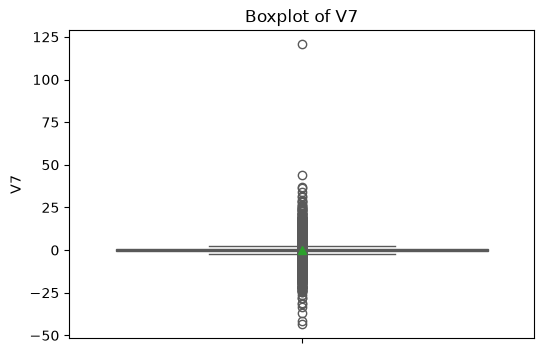

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\3340104099.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=df[d], palette="Set2", showmeans=True)


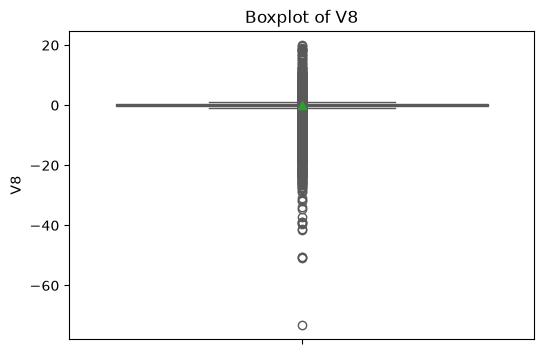

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\3340104099.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=df[d], palette="Set2", showmeans=True)


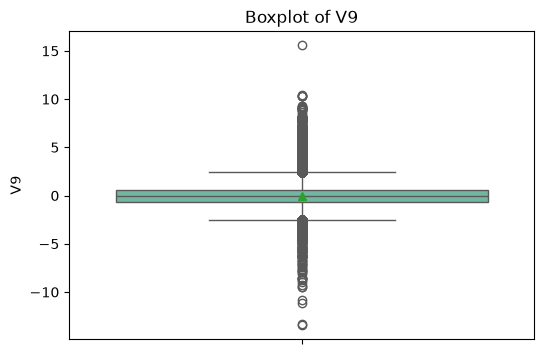

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\3340104099.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=df[d], palette="Set2", showmeans=True)


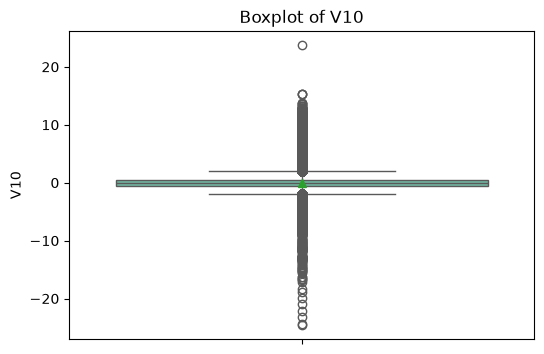

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\3340104099.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=df[d], palette="Set2", showmeans=True)


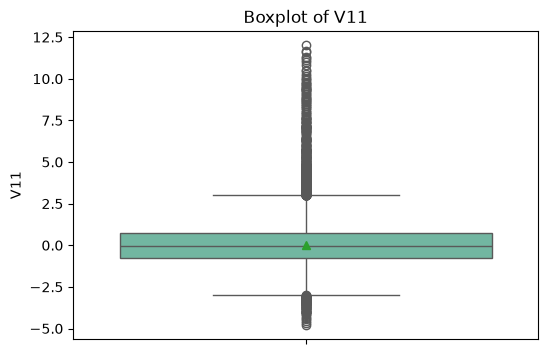

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\3340104099.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=df[d], palette="Set2", showmeans=True)


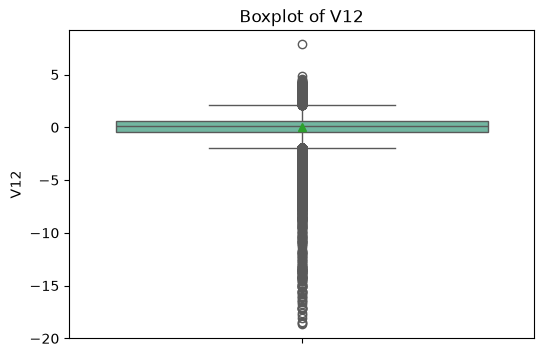

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\3340104099.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=df[d], palette="Set2", showmeans=True)


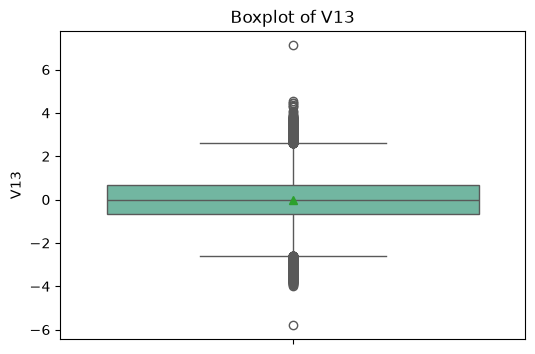

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\3340104099.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=df[d], palette="Set2", showmeans=True)


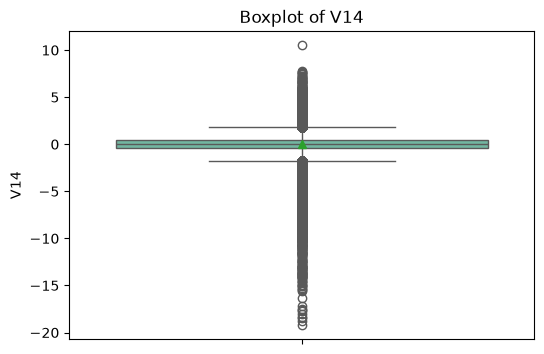

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\3340104099.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=df[d], palette="Set2", showmeans=True)


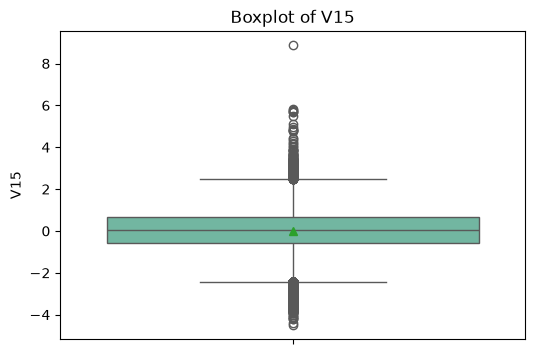

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\3340104099.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=df[d], palette="Set2", showmeans=True)


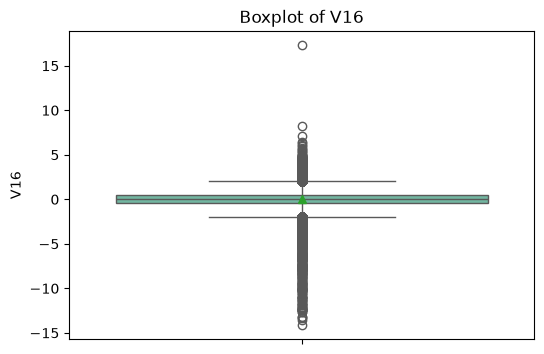

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\3340104099.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=df[d], palette="Set2", showmeans=True)


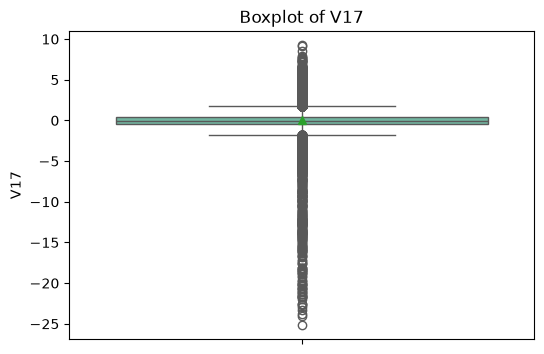

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\3340104099.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=df[d], palette="Set2", showmeans=True)


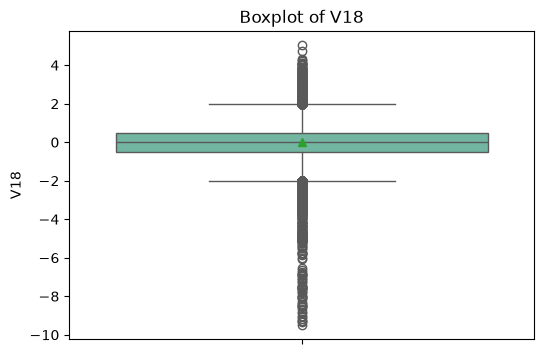

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\3340104099.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=df[d], palette="Set2", showmeans=True)


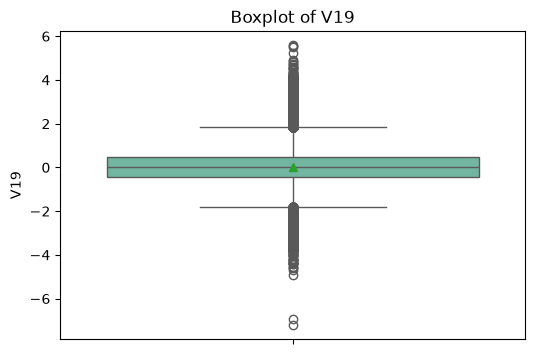

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\3340104099.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=df[d], palette="Set2", showmeans=True)


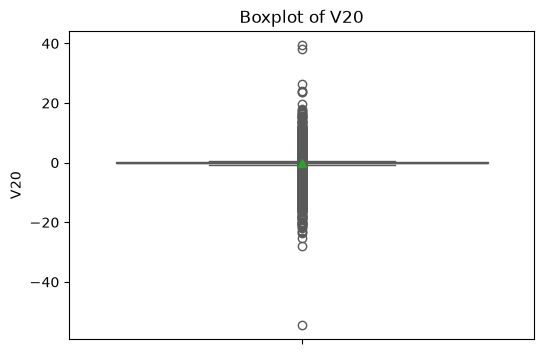

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\3340104099.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=df[d], palette="Set2", showmeans=True)


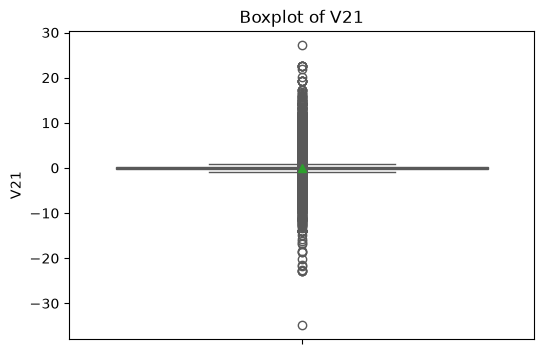

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\3340104099.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=df[d], palette="Set2", showmeans=True)


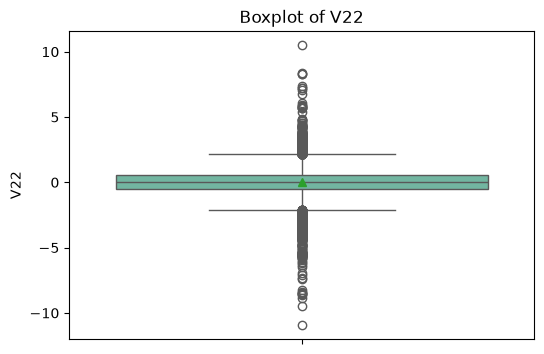

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\3340104099.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=df[d], palette="Set2", showmeans=True)


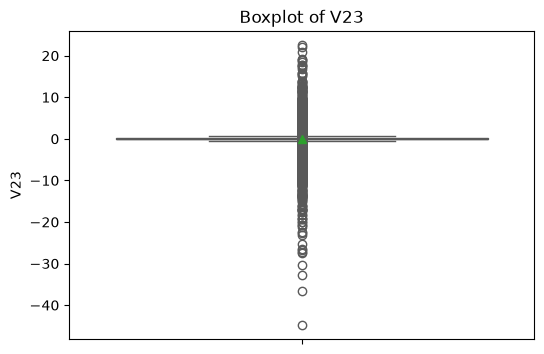

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\3340104099.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=df[d], palette="Set2", showmeans=True)


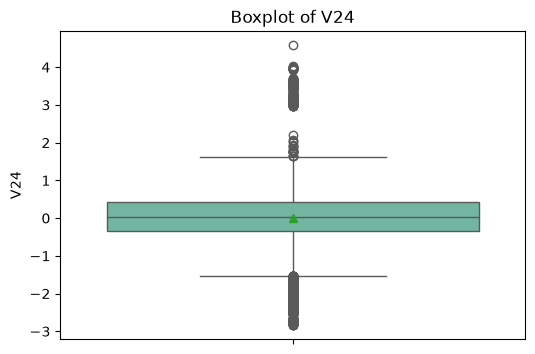

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\3340104099.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=df[d], palette="Set2", showmeans=True)


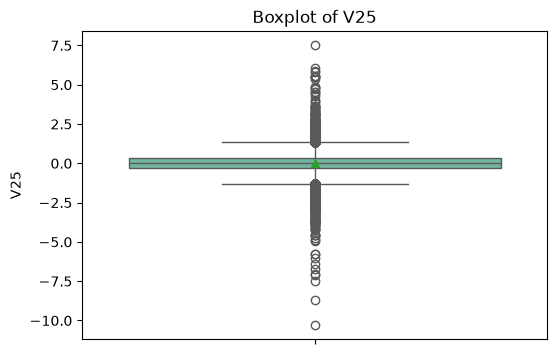

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\3340104099.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=df[d], palette="Set2", showmeans=True)


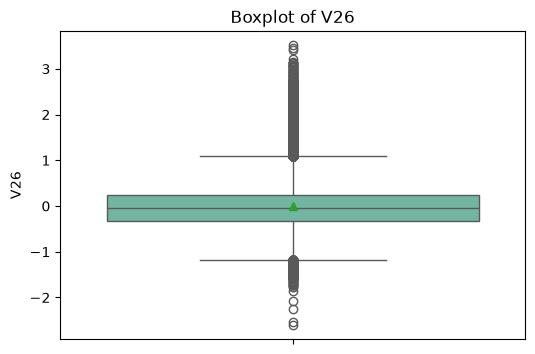

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\3340104099.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=df[d], palette="Set2", showmeans=True)


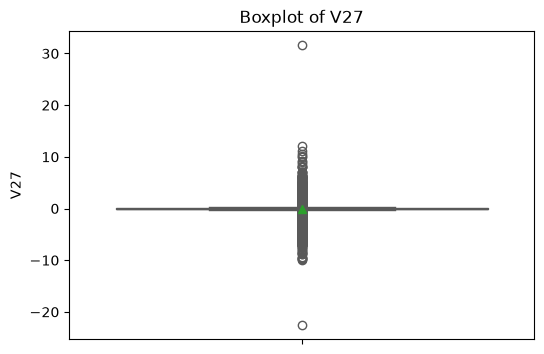

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\3340104099.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=df[d], palette="Set2", showmeans=True)


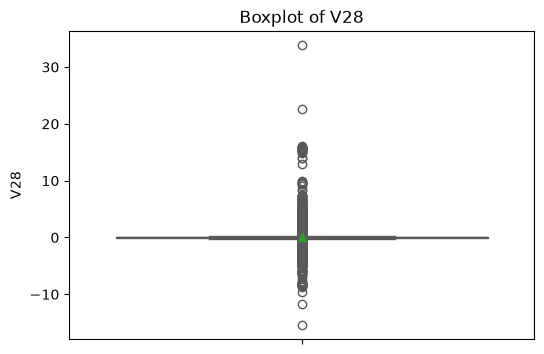

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\3340104099.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=df[d], palette="Set2", showmeans=True)


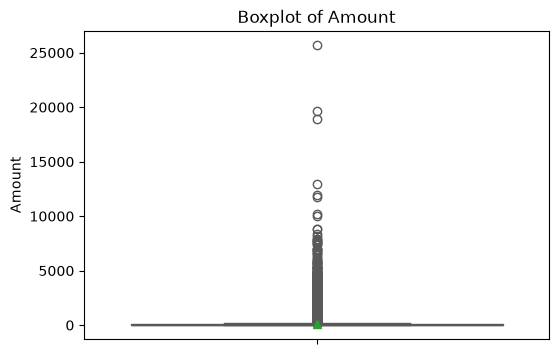

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\3340104099.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(y=df[d], palette="Set2", showmeans=True)


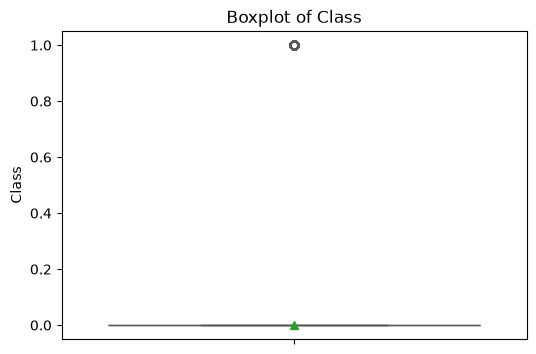

In [18]:
for d in df:
    plt.figure(figsize=(6,4))
    sns.boxplot(y=df[d], palette="Set2", showmeans=True)
    plt.title(f"Boxplot of {d}")
    plt.show()  

## Bivariate Analysis

In [19]:
for d in df:
    print(f"=== {d} ===")
    print(df.groupby("Class")[d].mean())

=== Time ===
Class
0    94835.058093
1    80450.513742
Name: Time, dtype: float64
=== V1 ===
Class
0    0.013439
1   -4.498280
Name: V1, dtype: float64
=== V2 ===
Class
0   -0.009829
1    3.405965
Name: V2, dtype: float64
=== V3 ===
Class
0    0.012853
1   -6.729599
Name: V3, dtype: float64
=== V4 ===
Class
0   -0.010440
1    4.472591
Name: V4, dtype: float64
=== V5 ===
Class
0    0.006769
1   -2.957197
Name: V5, dtype: float64
=== V6 ===
Class
0    0.001251
1   -1.432518
Name: V6, dtype: float64
=== V7 ===
Class
0    0.010447
1   -5.175912
Name: V7, dtype: float64
=== V8 ===
Class
0   -0.002448
1    0.953255
Name: V8, dtype: float64
=== V9 ===
Class
0    0.002613
1   -2.522124
Name: V9, dtype: float64
=== V10 ===
Class
0    0.007663
1   -5.453274
Name: V10, dtype: float64
=== V11 ===
Class
0   -0.006004
1    3.716347
Name: V11, dtype: float64
=== V12 ===
Class
0    0.009476
1   -6.103254
Name: V12, dtype: float64
=== V13 ===
Class
0    0.000762
1   -0.094324
Name: V13, dtype: float64


## Multivariate Analysis

In [20]:
features=df.drop(columns=["Time"]).columns.tolist()
cor=df[features].corr()
print(cor)

              V1        V2        V3        V4        V5        V6        V7  \
V1      1.000000  0.006875 -0.008112  0.002257 -0.007036  0.000413 -0.009173   
V2      0.006875  1.000000  0.005278 -0.001495  0.005210 -0.000594  0.007425   
V3     -0.008112  0.005278  1.000000  0.002829 -0.006879 -0.001511 -0.011721   
V4      0.002257 -0.001495  0.002829  1.000000  0.001744 -0.000880  0.004657   
V5     -0.007036  0.005210 -0.006879  0.001744  1.000000 -0.000938 -0.008709   
V6      0.000413 -0.000594 -0.001511 -0.000880 -0.000938  1.000000  0.000436   
V7     -0.009173  0.007425 -0.011721  0.004657 -0.008709  0.000436  1.000000   
V8     -0.001168  0.002899 -0.001815  0.000890  0.001430  0.003036 -0.006419   
V9      0.001828 -0.000274 -0.003579  0.002154 -0.001213 -0.000734 -0.004921   
V10     0.000815  0.000620 -0.009632  0.002753 -0.006050 -0.002180 -0.013617   
V11     0.001028 -0.000633  0.002339 -0.001223  0.000411 -0.000211  0.002454   
V12    -0.001524  0.002266 -0.005900  0.

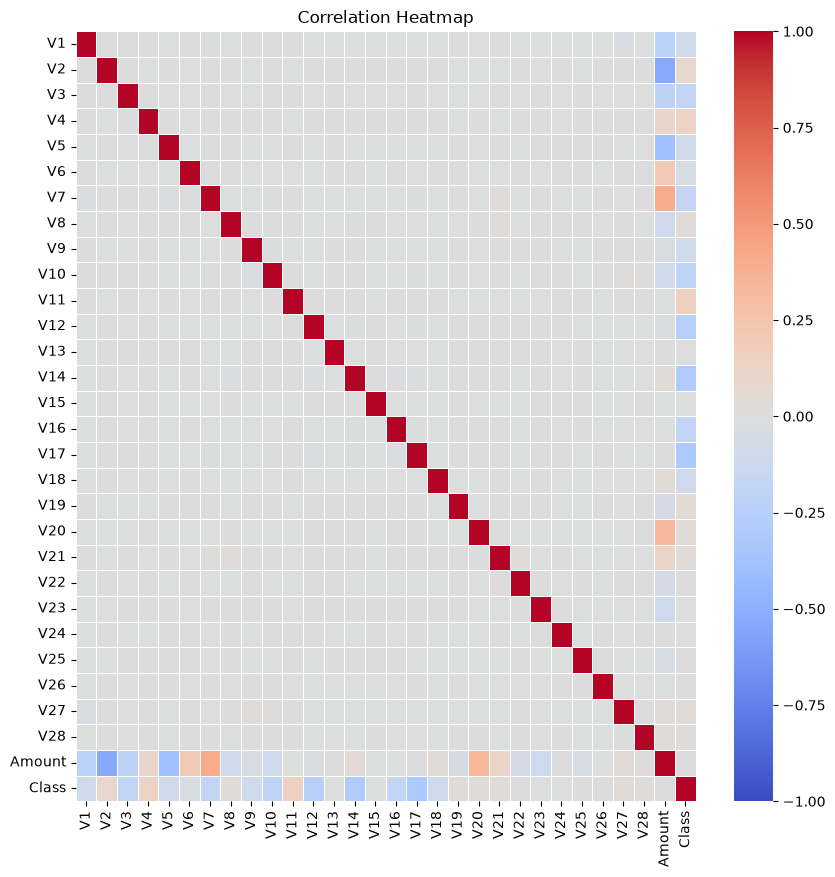

In [21]:
plt.figure(figsize=(10,10))
sns.heatmap(cor, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

## Outlier and skewness

In [22]:
df_zscore=stats.zscore(df)
print(df_zscore[df_zscore>=4])

[5.24953109 6.35911826 5.62331048 ... 6.19666165 4.048299   4.85887895]


C:\Users\ali\AppData\Local\Temp\ipykernel_15392\2018147225.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.kdeplot(df[d], fill=True, palette="Set2")


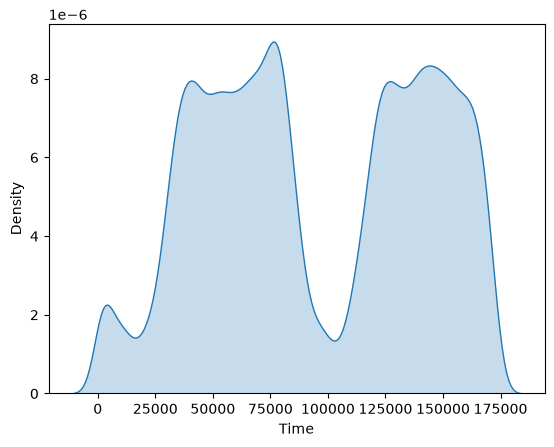

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\2018147225.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.kdeplot(df[d], fill=True, palette="Set2")


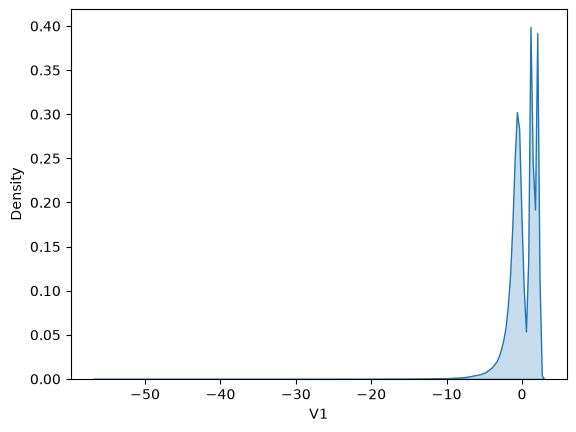

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\2018147225.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.kdeplot(df[d], fill=True, palette="Set2")


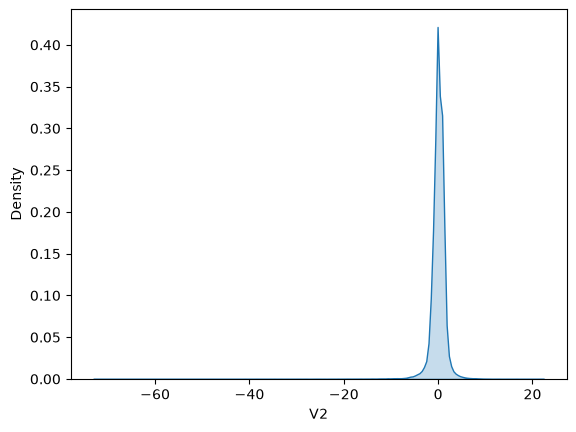

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\2018147225.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.kdeplot(df[d], fill=True, palette="Set2")


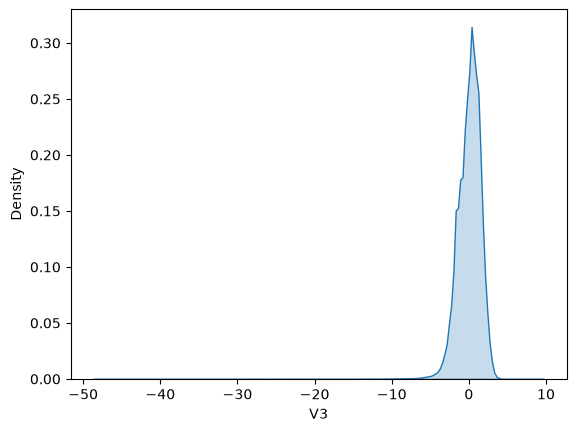

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\2018147225.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.kdeplot(df[d], fill=True, palette="Set2")


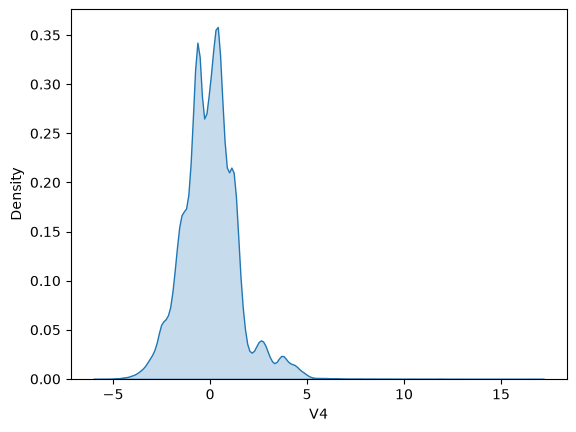

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\2018147225.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.kdeplot(df[d], fill=True, palette="Set2")


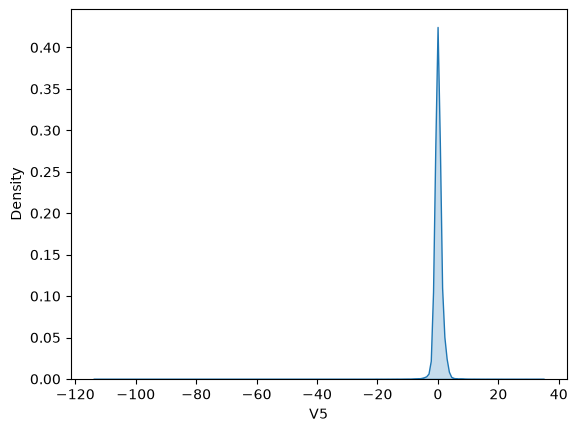

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\2018147225.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.kdeplot(df[d], fill=True, palette="Set2")


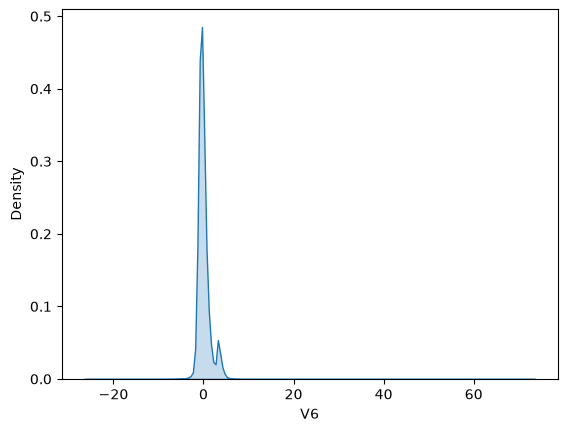

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\2018147225.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.kdeplot(df[d], fill=True, palette="Set2")


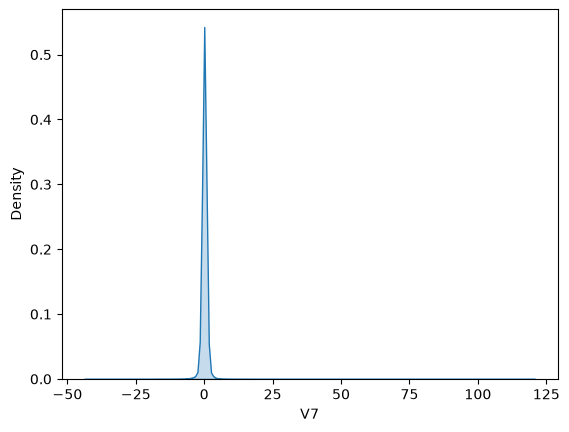

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\2018147225.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.kdeplot(df[d], fill=True, palette="Set2")


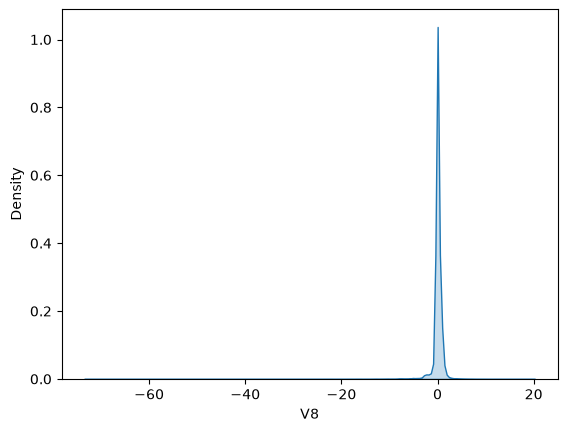

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\2018147225.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.kdeplot(df[d], fill=True, palette="Set2")


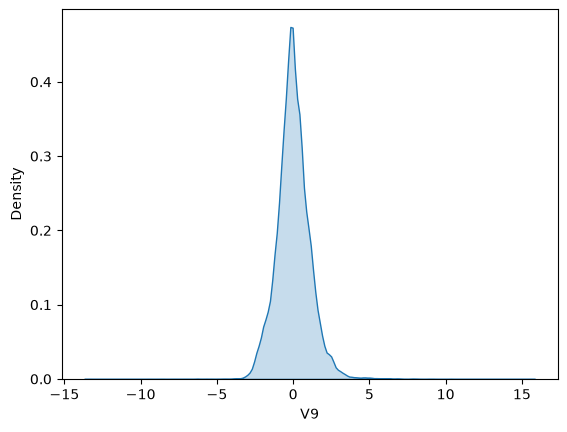

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\2018147225.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.kdeplot(df[d], fill=True, palette="Set2")


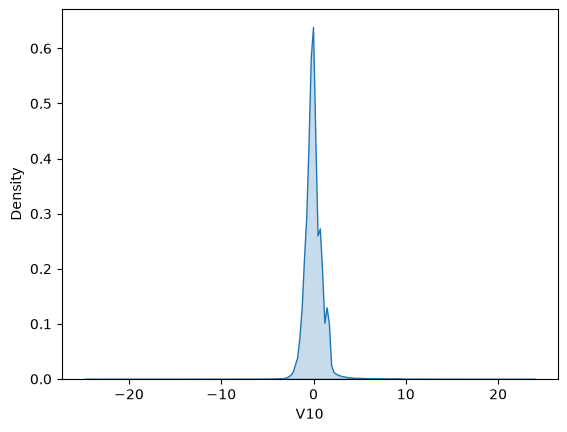

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\2018147225.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.kdeplot(df[d], fill=True, palette="Set2")


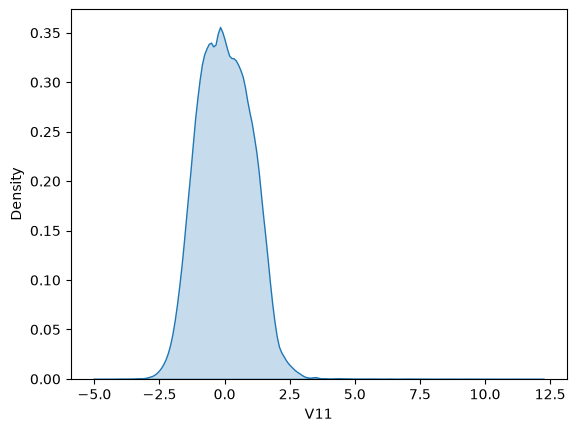

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\2018147225.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.kdeplot(df[d], fill=True, palette="Set2")


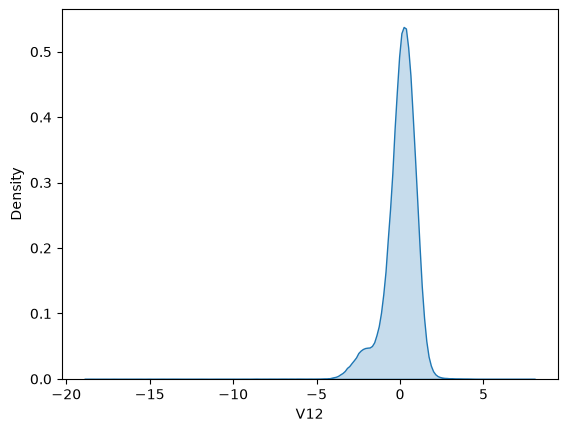

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\2018147225.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.kdeplot(df[d], fill=True, palette="Set2")


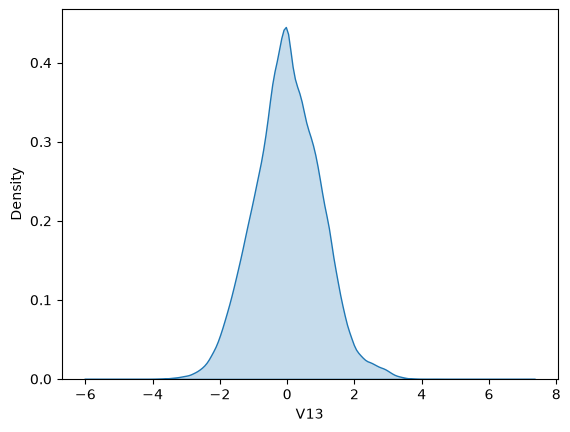

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\2018147225.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.kdeplot(df[d], fill=True, palette="Set2")


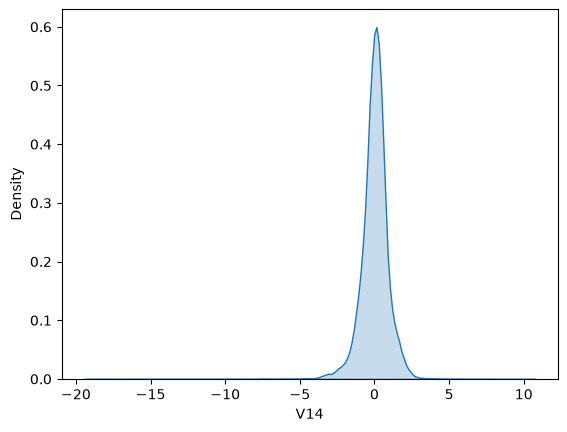

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\2018147225.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.kdeplot(df[d], fill=True, palette="Set2")


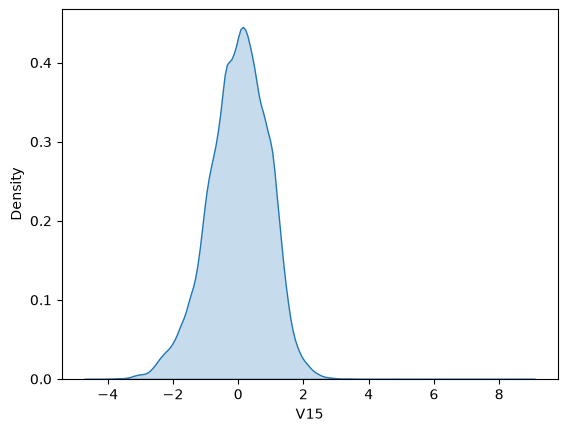

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\2018147225.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.kdeplot(df[d], fill=True, palette="Set2")


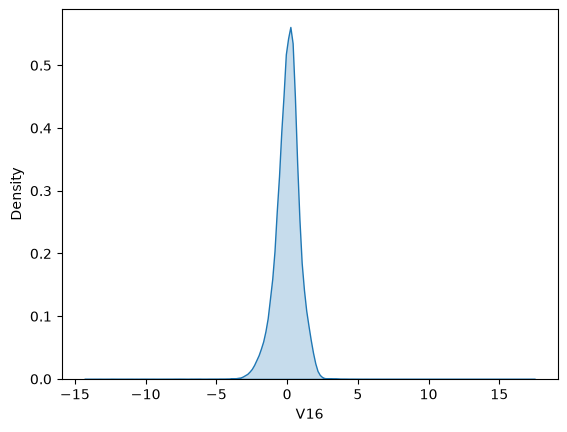

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\2018147225.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.kdeplot(df[d], fill=True, palette="Set2")


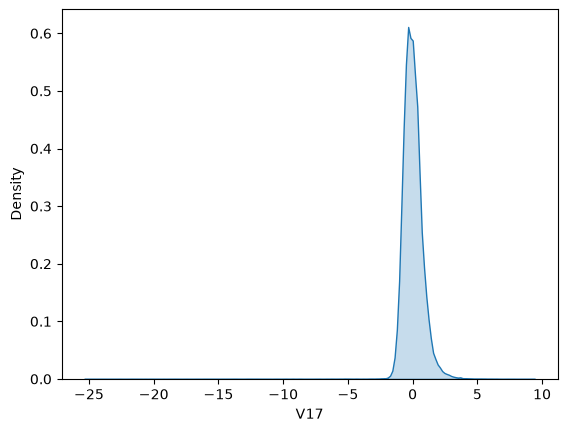

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\2018147225.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.kdeplot(df[d], fill=True, palette="Set2")


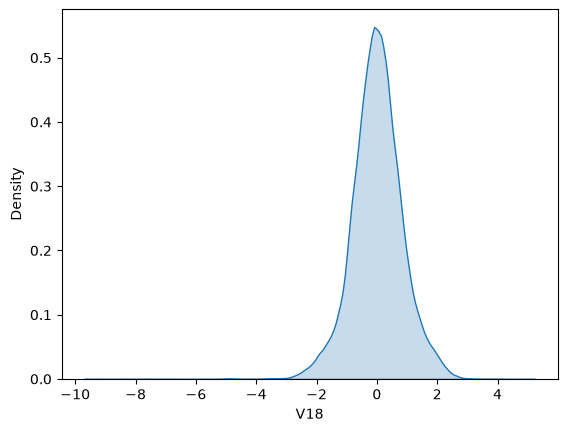

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\2018147225.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.kdeplot(df[d], fill=True, palette="Set2")


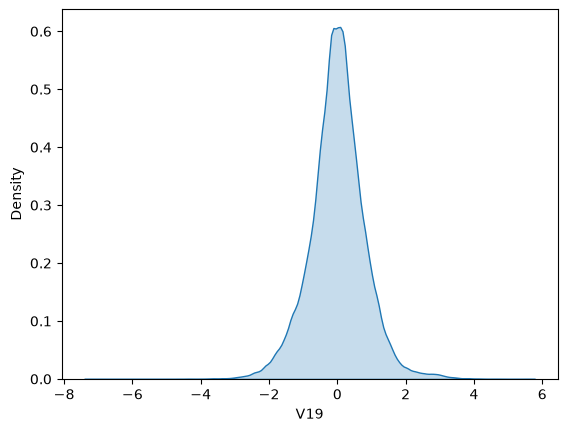

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\2018147225.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.kdeplot(df[d], fill=True, palette="Set2")


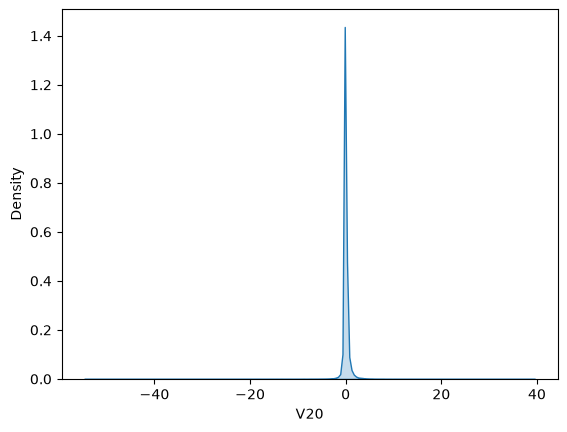

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\2018147225.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.kdeplot(df[d], fill=True, palette="Set2")


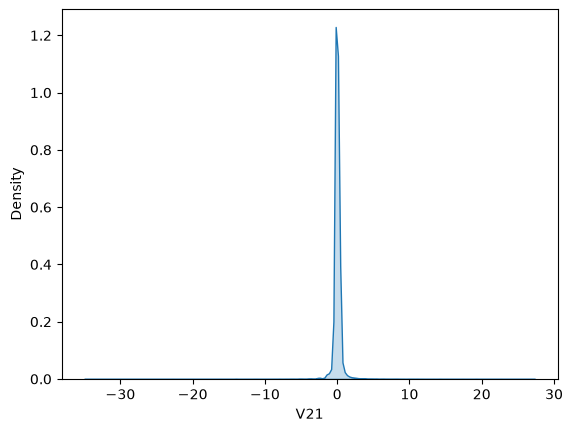

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\2018147225.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.kdeplot(df[d], fill=True, palette="Set2")


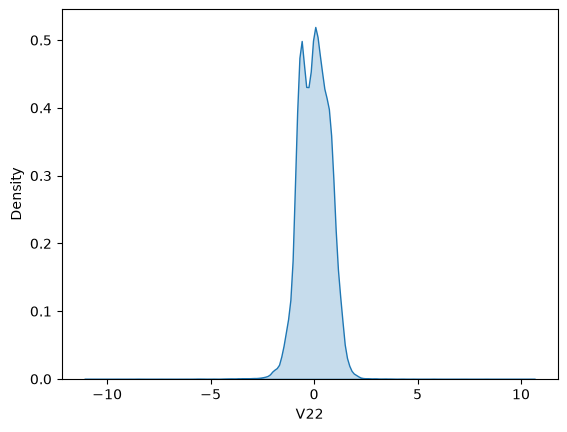

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\2018147225.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.kdeplot(df[d], fill=True, palette="Set2")


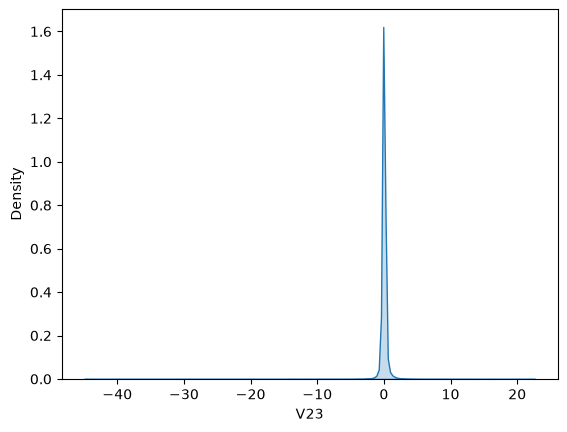

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\2018147225.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.kdeplot(df[d], fill=True, palette="Set2")


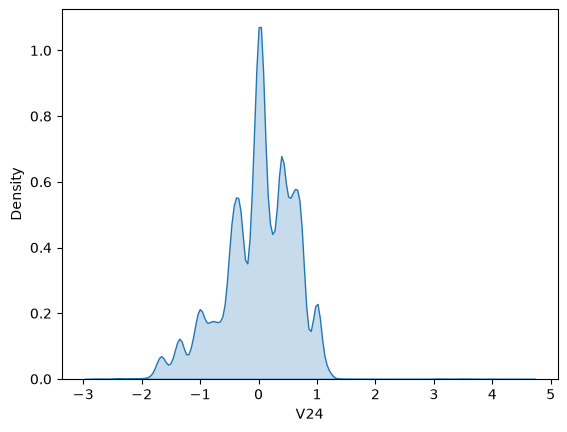

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\2018147225.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.kdeplot(df[d], fill=True, palette="Set2")


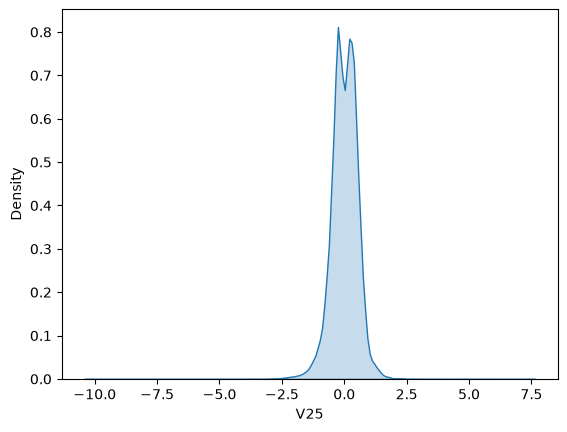

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\2018147225.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.kdeplot(df[d], fill=True, palette="Set2")


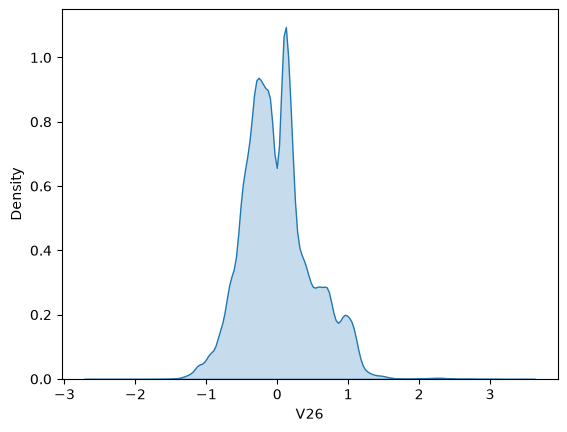

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\2018147225.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.kdeplot(df[d], fill=True, palette="Set2")


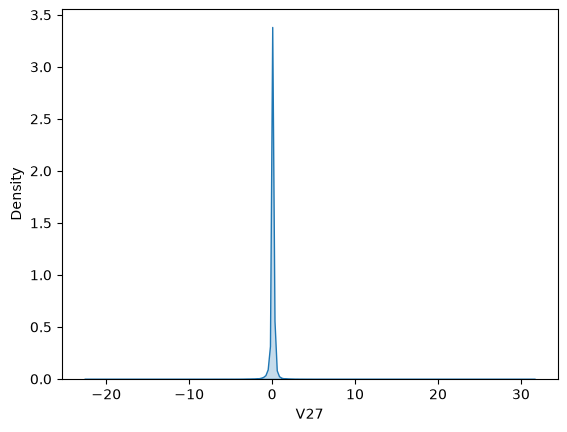

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\2018147225.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.kdeplot(df[d], fill=True, palette="Set2")


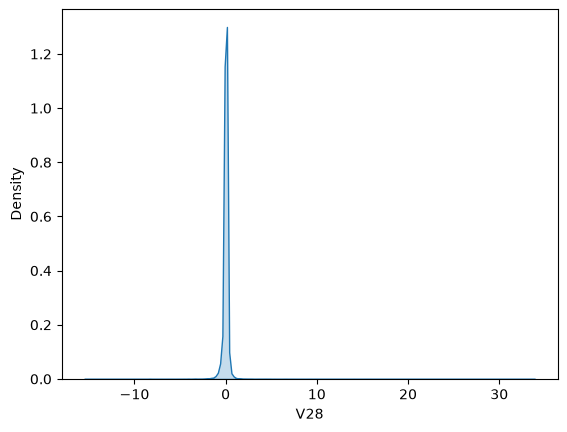

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\2018147225.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.kdeplot(df[d], fill=True, palette="Set2")


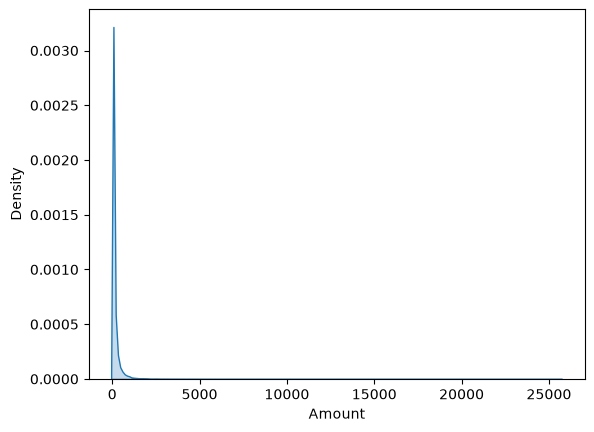

C:\Users\ali\AppData\Local\Temp\ipykernel_15392\2018147225.py:2: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.kdeplot(df[d], fill=True, palette="Set2")


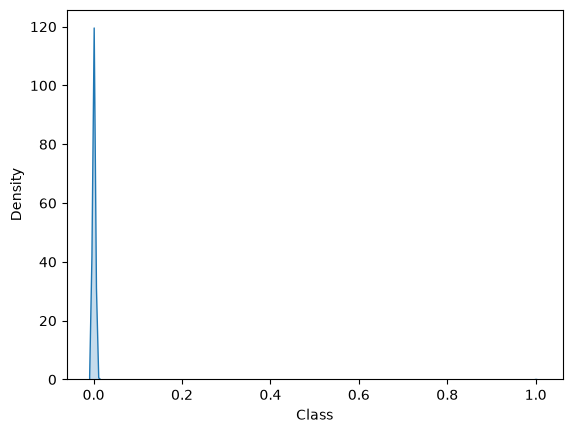

In [23]:
for d in df:
    sns.kdeplot(df[d], fill=True, palette="Set2")
    plt.show()

## Feature Engineering

In [5]:
df.drop(columns=["Time"], inplace=True)

## Splitting Data

In [6]:
X=df.drop(columns=["Class"])
Y=df["Class"]

X_train, X_test, Y_train, Y_test=train_test_split(X, Y, test_size=0.3, random_state=42, stratify=Y)

## SMOTE

In [7]:
print(f"Original training class distribution: {Counter(Y_train)}")
smote=SMOTE(random_state=42, sampling_strategy=0.5)
X_train_resampled, Y_train_resampled=smote.fit_resample(X_train, Y_train)
print(f"Resampled training class distribution: {Counter(Y_train_resampled)}")

Original training class distribution: Counter({0: 198277, 1: 331})
Resampled training class distribution: Counter({0: 198277, 1: 99138})


## Final Verifications

In [42]:
nullTrX=X_train_resampled.isnull().sum()
nullTrY=Y_train_resampled.isnull().sum()
print(nullTrX[nullTrX>0])
print(nullTrY[nullTrY>0])

Series([], dtype: int64)
[]


In [44]:
infTrX=np.isinf(X_train_resampled).sum()
infTrY=np.isinf(Y_train_resampled).sum()
print(infTrX[infTrX>0])
print(infTrY[infTrY>0])

Series([], dtype: int64)
[]


In [8]:
X_train_resampled.to_csv("X_train.csv", index=False)
Y_train_resampled.to_csv("Y_train.csv", index=False)
X_test.to_csv("X_test.csv", index=False)
Y_test.to_csv("Y_test.csv", index=False)